Subquestion: How did sepsis MCC discharge shares change from 2018 to 2024, and did trends differ between hospitals in regions classified as AI-adoption hotspots and coldspots in 2023-2024?

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
DATA_FILES = [Path("hospital_data_expanded.csv")]

#col names
CCN_COL = "Rndrng_Prvdr_CCN"
YEAR_COL = "data_year"
DRG_COL = "DRG_Cd"
COUNT_COL = "Tot_Dschrgs"
HSA_COL = "hsa_id"
CLASS_COL = "hsa_classification"

HOT_LABEL = 1
COLD_LABEL = -1

YEARS = list(range(2018, 2025))
REFERENCE_YEAR = 2018

N_BOOTSTRAPS = 1000  #100 for code test, update later
RANDOM_SEED = 42

OUTPUT_DIR = Path("sepsis_results")
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", None)

loading data

In [4]:
frames = []

for path in DATA_FILES:
    frame = pd.read_csv(path, dtype="string")
    frame.columns = frame.columns.str.strip()
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True)

column_mapping = {
    CCN_COL: "hospital",
    YEAR_COL: "year",
    DRG_COL: "drg",
    COUNT_COL: "discharges",
    HSA_COL: "hsa",
    CLASS_COL: "classification"
}

data = raw[list(column_mapping)].rename(columns=column_mapping).copy()

#standardize

for col in ["year", "drg", "classification"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data["discharges"] = pd.to_numeric(
    data["discharges"].str.replace(",", "", regex=False),
    errors="coerce"
)

#sepsis data

data = data.loc[
    data["year"].isin(YEARS)
    & data["drg"].isin([871, 872])
].copy()

data["year"] = data["year"].astype(int)
data["drg"] = data["drg"].astype(int)

print("Sepsis rows loaded:", len(data))

missing_years = set(YEARS) - set(data["year"].unique())

if missing_years:
    raise ValueError(f"Missing study years: {sorted(missing_years)}")

display(data.head())

Sepsis rows loaded: 8475


,hospital,year,drg,discharges,hsa,classification
123,010001,2018,871,505,1026,-1
124,010001,2018,872,110,1026,-1
150,010007,2018,871,16,1065,-1
151,010007,2018,872,16,1065,-1
232,010040,2018,871,346,1039,1


In [5]:
# standardizing across years

data["hsa_original"] = data["hsa"]

# find each hospital's latest year with a known HSA
# this is in response to ValueError: some hospitals changing HSAs (below)
known_hsa = data.loc[data["hsa"].notna()].copy()
latest_year = (
    known_hsa.groupby("hospital")["year"]
    .transform("max")
)
latest_hsa = (
    known_hsa.loc[
        known_hsa["year"].eq(latest_year),
        ["hospital", "hsa"]
    ]
    .drop_duplicates()
)

# check if latest year itself has conflicting assignments
if latest_hsa["hospital"].duplicated().any():
    raise ValueError("Multiple HSAs in a hospital's latest year")

hsa_lookup = latest_hsa.set_index("hospital")["hsa"]

# assign a fixed HSA across each hospital's records
data["hsa"] = data["hospital"].map(hsa_lookup)

# check for duplicate records
keys = ["hospital", "year", "drg"]
duplicates = data.loc[data.duplicated(keys, keep=False)]
if not duplicates.empty:
    display(duplicates.sort_values(keys).head(30))
    raise ValueError("Duplicate hospital–year–DRG records found")

# check: a hospital has to have one HSA and one classification
# resolved by latest_year/hsa code above
hospital_checks = (
    data.groupby("hospital")
    .agg(
        n_hsas=("hsa", "nunique"),
        n_classes=("classification", "nunique")
    )
)
inconsistent = hospital_checks.loc[
    (hospital_checks["n_hsas"] > 1)
    | (hospital_checks["n_classes"] > 1)
]
if not inconsistent.empty:
    display(inconsistent)
    raise ValueError(
        "Some hospitals change HSA or classification"
    )

# check that each HSA has one classification
hsa_checks = data.groupby("hsa")["classification"].nunique()
if (hsa_checks > 1).any():
    raise ValueError("At least one HSA has conflicting classifications")

print("Classification counts before filtering:")
display(data["classification"].value_counts(dropna=False))

eligible = data.loc[
    data["classification"].isin([HOT_LABEL, COLD_LABEL])
    & data["hospital"].notna()
    & data["hsa"].notna()
].copy()

# report missing discharge values
print(
    "Rows with missing discharge counts:",
    eligible["discharges"].isna().sum()
)


Classification counts before filtering:


classification
1     5590
-1    2885
Name: count, dtype: Int64

Rows with missing discharge counts: 0


calculating hospital-year MCC shares

In [6]:
counts = eligible.pivot(
    index=["hospital", "year"],
    columns="drg",
    values="discharges"
).reindex(columns=[871, 872])

metadata = (
    eligible.groupby(["hospital", "year"], as_index=False)
    .agg(
        hsa=("hsa", "first"),
        classification=("classification", "first")
    )
)

panel = (
    counts.rename(columns={871: "n_871", 872: "n_872"})
    .reset_index()
    .merge(
        metadata,
        on=["hospital", "year"],
        how="left",
        validate="one_to_one"
    )
)

panel["group"] = np.where(
    panel["classification"] == HOT_LABEL,
    "Hotspot",
    "Coldspot"
)

panel["complete"] = panel[["n_871", "n_872"]].notna().all(axis=1)

coverage = (
    panel.groupby(["year", "group"])
    .agg(
        observed_hospitals=("hospital", "nunique"),
        complete_hospitals=("complete", "sum")
    )
    .reset_index()
)

coverage["excluded_hospitals"] = (
    coverage["observed_hospitals"] - coverage["complete_hospitals"]
)

coverage["retention_pct"] = (
    100 * coverage["complete_hospitals"]
    / coverage["observed_hospitals"]
)

display(coverage)

# **observed_hospitals counts hospitals with at least-
# -one reported sepsis code, not all hospitals in the CMS data

complete_panel = panel.loc[panel["complete"]].copy()

complete_panel["sepsis_discharges"] = (
    complete_panel["n_871"] + complete_panel["n_872"]
)

complete_panel["mcc_share"] = (
    complete_panel["n_871"]
    / complete_panel["sepsis_discharges"]
)

# % units
complete_panel["mcc_pct"] = 100 * complete_panel["mcc_share"]

# Primary sample: at least two calculable years per hospital
years_per_hospital = (
    complete_panel.groupby("hospital")["year"].nunique()
)

primary_ids = years_per_hospital[
    years_per_hospital >= 2
].index

primary = complete_panel.loc[
    complete_panel["hospital"].isin(primary_ids)
].copy()

# Sensitivity sample: complete in all seven years
balanced_ids = years_per_hospital[
    years_per_hospital == len(YEARS)
].index

balanced = complete_panel.loc[
    complete_panel["hospital"].isin(balanced_ids)
].copy()

print("Primary hospital-year observations:", len(primary))
print("Primary distinct hospitals:", primary["hospital"].nunique())
print("Balanced distinct hospitals:", balanced["hospital"].nunique())

,year,group,observed_hospitals,complete_hospitals,excluded_hospitals,retention_pct
0,2018,Coldspot,237,212,25,89.451477
1,2018,Hotspot,425,403,22,94.823529
2,2019,Coldspot,230,208,22,90.434783
3,2019,Hotspot,424,398,26,93.867925
4,2020,Coldspot,223,191,32,85.650224
5,2020,Hotspot,422,380,42,90.047393
6,2021,Coldspot,221,184,37,83.257919
7,2021,Hotspot,425,370,55,87.058824
8,2022,Coldspot,225,171,54,76.000000
9,2022,Hotspot,425,354,71,83.294118


Primary hospital-year observations: 3917
Primary distinct hospitals: 625
Balanced distinct hospitals: 468


annual trends summary

,year,group,hospitals,hsas,reported_sepsis_discharges,mean_mcc_pct,median_mcc_pct,sd_mcc_pct
0,2018,Coldspot,207,149,56663,76.13,78.65,9.55
1,2018,Hotspot,394,228,126763,78.13,78.6,5.67
2,2019,Coldspot,202,145,55060,77.17,78.85,8.18
3,2019,Hotspot,394,226,123543,78.41,78.94,5.68
4,2020,Coldspot,191,136,49068,79.85,81.94,9.18
5,2020,Hotspot,378,218,116232,81.47,82.05,5.7
6,2021,Coldspot,184,134,43310,80.19,82.27,8.35
7,2021,Hotspot,370,214,105656,81.5,81.99,5.75
8,2022,Coldspot,171,126,41729,81.43,83.4,8.53
9,2022,Hotspot,353,204,105163,82.89,83.75,5.0


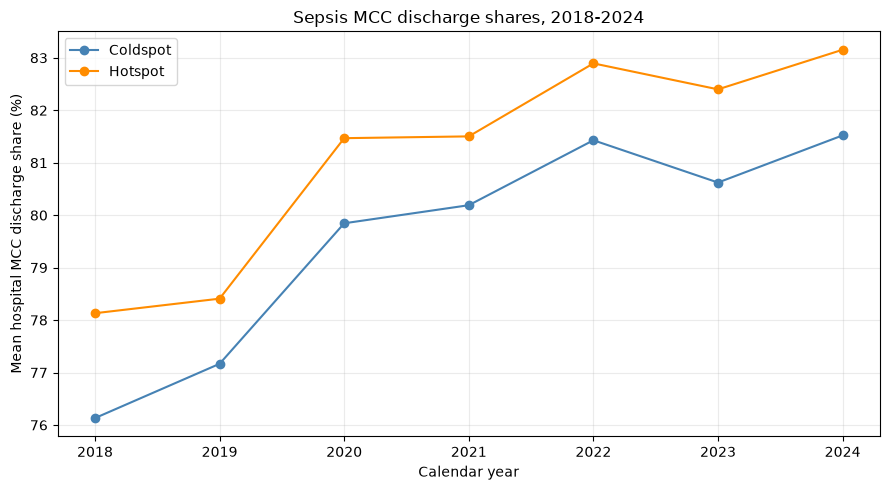

In [7]:
def annual_summary(frame):
    return (
        frame.groupby(["year", "group"])
        .agg(
            hospitals=("hospital", "nunique"),
            hsas=("hsa", "nunique"),
            reported_sepsis_discharges=("sepsis_discharges", "sum"),
            mean_mcc_pct=("mcc_pct", "mean"),
            median_mcc_pct=("mcc_pct", "median"),
            sd_mcc_pct=("mcc_pct", "std")
        )
        .reset_index()
    )

annual = annual_summary(primary)
display(annual.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

colors = {"Hotspot": "darkorange", "Coldspot": "steelblue"}

for group, subset in annual.groupby("group"):
    ax.plot(
        subset["year"],
        subset["mean_mcc_pct"],
        marker="o",
        label=group,
        color=colors[group]
    )

ax.set(
    xlabel="Calendar year",
    ylabel="Mean hospital MCC discharge share (%)",
    title="Sepsis MCC discharge shares, 2018-2024"
)

ax.set_xticks(YEARS)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "annual_mcc_shares.png",
    dpi=300
)

plt.show()

fitting hospital fixed-effects regression

In [8]:
MODEL_YEARS = [
    year for year in YEARS
    if year != REFERENCE_YEAR
]

def prepare_fixed_effects(frame):
    frame = frame.reset_index(drop=True).copy()

    # Require observations from both classes in each year
    year_groups = (
        frame.groupby(["year", "group"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=YEARS,
            columns=["Coldspot", "Hotspot"],
            fill_value=0
        )
    )

    hotspot = (
        frame["classification"].eq(HOT_LABEL)
        .astype(float)
        .to_numpy()
    )

    X = pd.DataFrame(index=frame.index)

    for year in MODEL_YEARS:
        year_indicator = frame["year"].eq(year).astype(float)

        X[f"year_{year}"] = year_indicator
        X[f"hotspot_x_{year}"] = year_indicator * hotspot

    y = frame["mcc_pct"].astype(float)

    # Within-hospital demeaning
    X_within = X - X.groupby(frame["hospital"]).transform("mean")
    y_within = y - y.groupby(frame["hospital"]).transform("mean")

    return (
        frame,
        X_within.to_numpy(dtype=float),
        y_within.to_numpy(dtype=float),
        X.columns.tolist()
    )


def fit_coefficients(X, y):
    if np.linalg.matrix_rank(X) < X.shape[1]:
        raise ValueError(
            "Model is not identifiable in this sample."
        )

    beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    return beta


model_frame, X, y, feature_names = prepare_fixed_effects(primary)
beta = fit_coefficients(X, y)

coefficient_table = pd.DataFrame({
    "term": feature_names,
    "estimate_pp": beta
})

display(coefficient_table)

,term,estimate_pp
0,year_2019,0.913957
1,hotspot_x_2019,-0.648959
2,year_2020,3.099189
3,hotspot_x_2020,0.077238
4,year_2021,3.015661
5,hotspot_x_2021,0.343328
6,year_2022,4.472747
7,hotspot_x_2022,0.192486
8,year_2023,3.594306
9,hotspot_x_2023,0.744346


HSA-level bootstrap CIs

In [9]:
def bootstrap_fixed_effects(frame, n_bootstraps, seed):
    model_frame, X, y, names = prepare_fixed_effects(frame)
    point_estimate = fit_coefficients(X, y)

    # Enforce that each hospital belongs to a single HSA.
    if (
        model_frame.groupby("hospital")["hsa"].nunique() > 1
    ).any():
        raise ValueError("Hospital identifiers cross HSA boundaries.")

    hsa_groups = (
        model_frame[["hsa", "group"]]
        .drop_duplicates()
    )

    if hsa_groups["hsa"].duplicated().any():
        raise ValueError("An HSA belongs to multiple classes.")

    group_hsas = {
        group: subset["hsa"].to_numpy()
        for group, subset in hsa_groups.groupby("group")
    }

    cluster_counts = {
        group: len(hsas)
        for group, hsas in group_hsas.items()
    }

    print("HSAs available for bootstrap:", cluster_counts)

    if any(count < 2 for count in cluster_counts.values()):
        raise ValueError(
            "At least two HSAs per group are required; "
            "few HSAs still make inference unreliable."
        )

    cluster_indices = (
        model_frame.groupby("hsa", sort=False).indices
    )

    rng = np.random.default_rng(seed)
    estimates = []
    failed = 0

    for b in range(n_bootstraps):
        sampled_hsas = []

        for group in ["Coldspot", "Hotspot"]:
            hsas = group_hsas[group]

            sampled_hsas.extend(
                rng.choice(hsas, size=len(hsas), replace=True)
            )

        row_indices = np.concatenate([
            cluster_indices[hsa] for hsa in sampled_hsas
        ])

        try:
            estimates.append(
                fit_coefficients(X[row_indices], y[row_indices])
            )
        except ValueError:
            failed += 1

        if (b + 1) % 200 == 0:
            print(f"Completed {b + 1}/{n_bootstraps}")

    if not estimates:
        raise ValueError("No identifiable bootstrap models.")

    bootstrap_estimates = np.vstack(estimates)

    if failed / n_bootstraps > 0.05:
        raise ValueError(
            f"{failed} bootstrap models were not identifiable. "
            "Review coverage before interpreting intervals."
        )

    lower, upper = np.quantile(
        bootstrap_estimates,
        [0.025, 0.975],
        axis=0
    )

    results = pd.DataFrame({
        "term": names,
        "estimate_pp": point_estimate,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper
    })

    print("Successful bootstrap samples:", len(estimates))
    print("Non-identifiable samples:", failed)

    return results


results = bootstrap_fixed_effects(
    primary,
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED
)

interaction_results = results.loc[
    results["term"].str.startswith("hotspot_x_")
].copy()

interaction_results["year"] = (
    interaction_results["term"]
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

display(
    interaction_results[
        ["year", "estimate_pp", "ci_lower_pp", "ci_upper_pp"]
    ].round(3)
)

HSAs available for bootstrap: {'Coldspot': 157, 'Hotspot': 229}
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000
Successful bootstrap samples: 1000
Non-identifiable samples: 0


,year,estimate_pp,ci_lower_pp,ci_upper_pp
1,2019,-0.649,-1.652,0.224
3,2020,0.077,-1.197,1.205
5,2021,0.343,-0.830,1.510
7,2022,0.192,-0.984,1.313
9,2023,0.744,-0.299,1.829
11,2024,0.418,-0.853,1.636


plotting adjusted differences

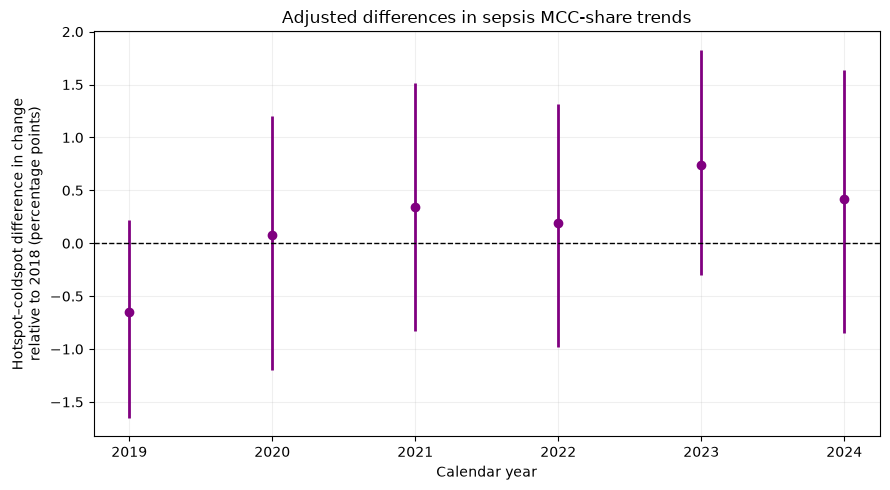

In [10]:
plot_data = interaction_results.sort_values("year")

fig, ax = plt.subplots(figsize=(9, 5))

# Draw intervals directly; percentile intervals do not
# necessarily contain the original point estimate.
ax.vlines(
    plot_data["year"],
    plot_data["ci_lower_pp"],
    plot_data["ci_upper_pp"],
    color="purple",
    linewidth=2
)

ax.scatter(
    plot_data["year"],
    plot_data["estimate_pp"],
    color="purple",
    zorder=3
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set(
    xlabel="Calendar year",
    ylabel="Hotspot–coldspot difference in change\n"
           "relative to 2018 (percentage points)",
    title="Adjusted differences in sepsis MCC-share trends"
)

ax.set_xticks(MODEL_YEARS)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "adjusted_trend_differences.png",
    dpi=300
)

plt.show()

analysis repeated only for hospitals with both DRGs reported in every year

In [11]:
balanced_counts = (
    balanced.groupby("group")
    .agg(
        hospitals=("hospital", "nunique"),
        hsas=("hsa", "nunique")
    )
)

display(balanced_counts)

balanced_results = None

if (
    {"Hotspot", "Coldspot"}.issubset(balanced_counts.index)
    and balanced_counts["hsas"].min() >= 2
):
    balanced_results = bootstrap_fixed_effects(
        balanced,
        n_bootstraps=N_BOOTSTRAPS,
        seed=RANDOM_SEED + 1
    )

    comparison = (
        results.loc[
            results["term"].str.startswith("hotspot_x_")
        ]
        .merge(
            balanced_results.loc[
                balanced_results["term"].str.startswith("hotspot_x_")
            ],
            on="term",
            suffixes=("_primary", "_balanced")
        )
    )

    display(comparison.round(3))

else:
    print(
        "Insufficient geographic coverage for the "
        "balanced-panel sensitivity analysis."
    )

,hospitals,hsas
group,,
Coldspot,144,105
Hotspot,324,196


HSAs available for bootstrap: {'Coldspot': 105, 'Hotspot': 196}
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000
Successful bootstrap samples: 1000
Non-identifiable samples: 0


,term,estimate_pp_primary,ci_lower_pp_primary,ci_upper_pp_primary,estimate_pp_balanced,ci_lower_pp_balanced,ci_upper_pp_balanced
0,hotspot_x_2019,-0.649,-1.652,0.224,-0.367,-1.331,0.559
1,hotspot_x_2020,0.077,-1.197,1.205,-0.477,-1.725,0.671
2,hotspot_x_2021,0.343,-0.830,1.510,-0.160,-1.434,1.126
3,hotspot_x_2022,0.192,-0.984,1.313,-0.238,-1.504,0.871
4,hotspot_x_2023,0.744,-0.299,1.829,0.342,-0.905,1.475
5,hotspot_x_2024,0.418,-0.853,1.636,0.056,-1.366,1.381


In [12]:
'''
coverage.to_csv(
    OUTPUT_DIR / "coverage.csv", index=False
)

primary.to_csv(
    OUTPUT_DIR / "sepsis_hospital_year_panel.csv", index=False
)

annual.to_csv(
    OUTPUT_DIR / "annual_summary.csv", index=False
)

results.to_csv(
    OUTPUT_DIR / "fixed_effects_results.csv", index=False
)

if balanced_results is not None:
    balanced_results.to_csv(
        OUTPUT_DIR / "balanced_panel_results.csv",
        index=False
    )
    '''

print(
    f"The primary analysis included {len(primary):,} hospital-year "
    f"observations from {primary['hospital'].nunique():,} hospitals "
    f"in {primary['hsa'].nunique():,} HSAs."
)

for group in ["Coldspot", "Hotspot"]:
    subset = annual.loc[annual["group"] == group].set_index("year")

    first = subset.loc[2018, "mean_mcc_pct"]
    last = subset.loc[2024, "mean_mcc_pct"]

    print(
        f"{group}: descriptive mean MCC share was "
        f"{first:.2f}% in 2018 and {last:.2f}% in 2024."
    )

estimate_2024 = interaction_results.loc[
    interaction_results["year"] == 2024
].iloc[0]

print(
    "\nThe adjusted hotspot–coldspot difference in change "
    "from 2018 to 2024 was "
    f"{estimate_2024['estimate_pp']:.2f} percentage points "
    f"(95% bootstrap CI "
    f"{estimate_2024['ci_lower_pp']:.2f} to "
    f"{estimate_2024['ci_upper_pp']:.2f})."
)

print(
    "\nDescriptive annual means may reflect changing hospital "
    "composition. The fixed-effects and balanced-panel analyses "
    "address different aspects of that concern."
)

The primary analysis included 3,917 hospital-year observations from 625 hospitals in 386 HSAs.
Coldspot: descriptive mean MCC share was 76.13% in 2018 and 81.52% in 2024.
Hotspot: descriptive mean MCC share was 78.13% in 2018 and 83.15% in 2024.

The adjusted hotspot–coldspot difference in change from 2018 to 2024 was 0.42 percentage points (95% bootstrap CI -0.85 to 1.64).

Descriptive annual means may reflect changing hospital composition. The fixed-effects and balanced-panel analyses address different aspects of that concern.
